In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from cnmodel.util import sound
from scipy.io import wavfile

--No graphics will be displayed.


## Sigmoid

In [2]:
def y(x, A, K, C, B, M):
    return A+ K/(C+np.exp(-B*(x-M)))

In [ ]:
A = 1
K = 1
C = 0.01
B = 0.02
M = -4.4

xs = np.linspace(10, 100, 50)
ys = np.array([y(x, A, K, C, B, M) for x in xs])

In [15]:
y0_lin = ys[0]
yn_lin = ys[-1]
y0_log = 1
yn_log = 100

b = (yn_log - y0_log) / np.log(yn_lin / y0_lin)
a = y0_log - b * np.log(y0_lin)

ys_log = a + b * np.log(ys)

In [21]:
x0_lin = xs[0]
xn_lin = xs[-1]
x0_log = 0
xn_log = 100

b = (xn_log - x0_log) / np.log(xn_lin / x0_lin)
a = x0_log - b * np.log(x0_lin)

xs_log = a + b * np.log(xs)

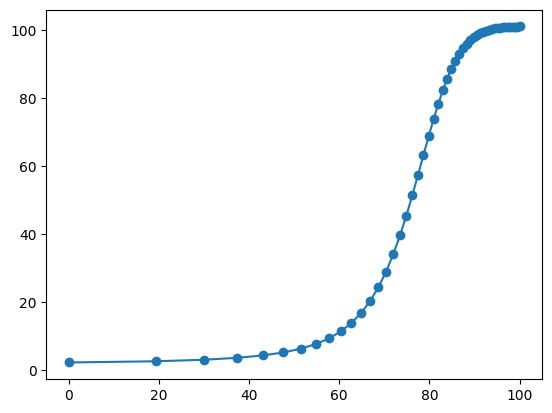

In [22]:
plt.plot(xs_log, ys, '-o')

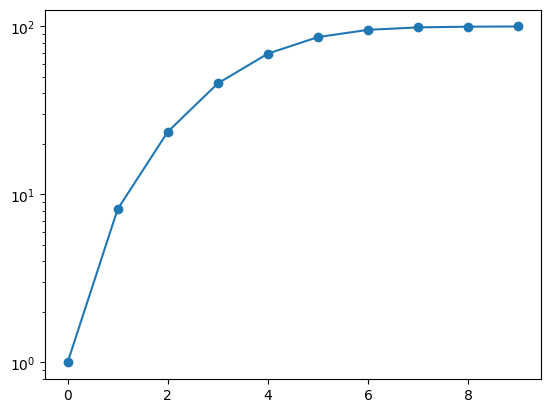

In [38]:
A = 1
K = 1
C = 0.01
B = 0.02  #0.02
M = 100  #-4.4

xs = np.linspace(10, 600, 10)
ys = np.array([y(x, A, K, C, B, M) for x in xs])

y0_lin = ys[0]
yn_lin = ys[-1]
y0_log = 1
yn_log = 100

b = (yn_log - y0_log) / np.log(yn_lin / y0_lin)
a = y0_log - b * np.log(y0_lin)

ys_log =  a + b * np.log(ys)

plt.plot(ys_log, '-o')
plt.yscale('log')

Text(0.5, 1.0, 'converted log sigmoid')

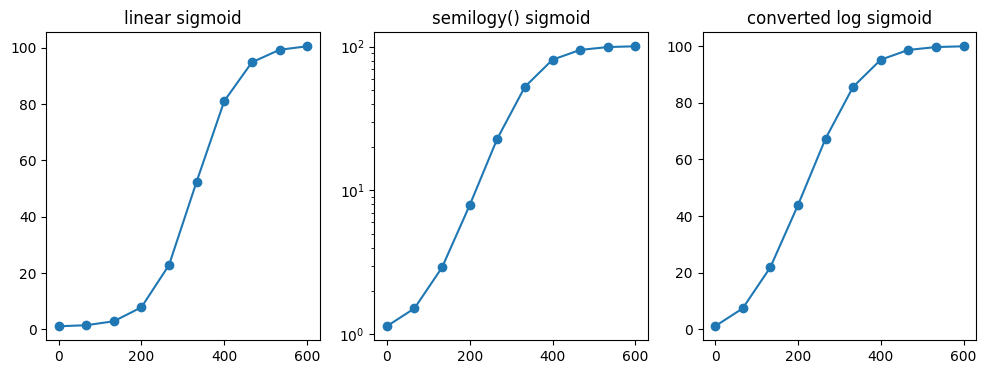

In [56]:
A = 1
K = 1
C = 0.01
B = 0.02  #0.02
M = 100  #-4.4

xs = np.linspace(0, 600, 10)
ys = np.array([y(x, A, K, C, B, M) for x in xs])

y0_lin = ys[0]
yn_lin = ys[-1]
y0_log = 1
yn_log = 100

b = (yn_log - y0_log) / np.log(yn_lin / y0_lin)
a = y0_log - b * np.log(y0_lin)

ys_log =  a + b * np.log(ys)

fig, axs = plt.subplots(1, 3, figsize=(12,4))
axs.ravel()

axs[0].plot(xs, ys, '-o')
axs[0].set_title('linear sigmoid')

axs[1].semilogy(xs, ys, '-o')
axs[1].set_title('semilogy() sigmoid')

axs[2].plot(xs, ys_log, '-o')
axs[2].set_title('converted log sigmoid')



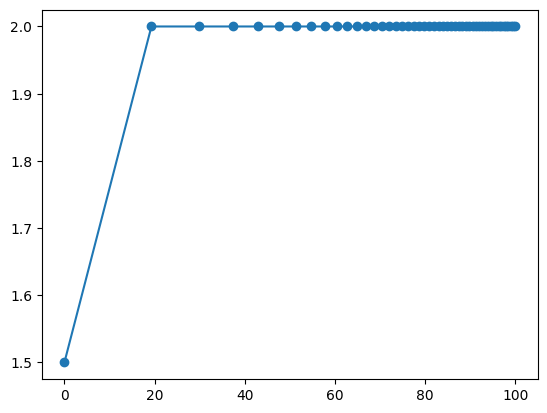

In [ ]:
A = 1
K = 1
C = 0.01
B = 0.02
M = -4.4

xs = np.linspace(10, 600, 50)
ys = np.array([y(x, A, K, C, B, M) for x in xs])

x0_lin = xs[0]
xn_lin = xs[-1]
x0_log = 0
xn_log = 100

b = (xn_log - x0_log) / np.log(xn_lin / x0_lin)
a = x0_log - b * np.log(x0_lin)

xs_log = a + b * np.log(xs)

plt.plot(xs_log, ys, '-o')

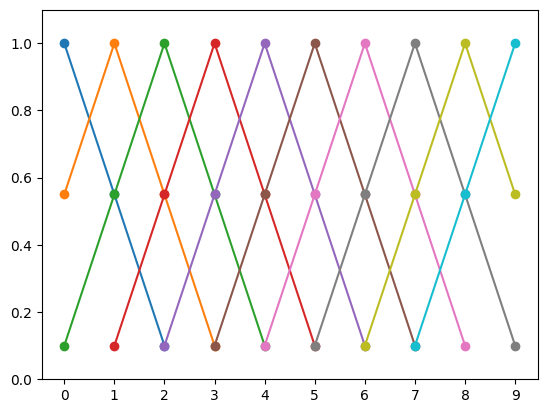

In [63]:
n_cells = 10
bf_scale = 0.45


for middle_i in range(n_cells):

    input_scales = [1 - bf_scale*np.abs(cell_i-middle_i) for cell_i in range(n_cells) if np.abs(cell_i-middle_i) <= 2]
    input_is = [cell_i for cell_i in range(n_cells) if np.abs(cell_i-middle_i) <= 2]
    plt.plot(input_is, input_scales, '-o')

plt.xticks([i for i in range(n_cells)]);
plt.ylim(0,1.1);

## Notch Noise

In [2]:
seed = 34657845
rng = np.random.default_rng(seed)

duration = 100 * 1e-3
dt = 0.01 * 1e-3
fs = 1 / dt

N = int(duration / dt)
t = np.arange(N) * dt

x = rng.standard_normal(N)
X = np.fft.rfft(x)
freq = np.fft.rfftfreq(N, d=dt)

center_freq = 22000
width = 1000

f_low = center_freq - width / 2
f_high = center_freq + width / 2
idx = (freq >= f_low) & (freq <= f_high)
X[idx] = 0

x = np.fft.irfft(X, n=N)
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

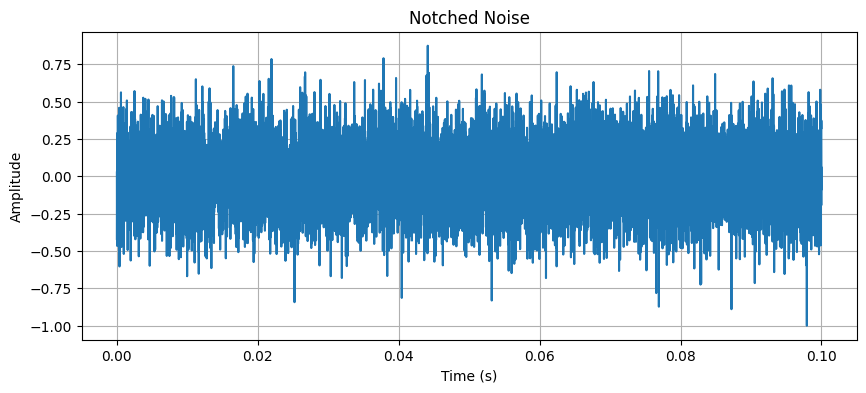

In [3]:
plt.figure(figsize=(10, 4))

plt.plot(t, x)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Notched Noise")

# plt.xlim(0, 5)
plt.grid()

plt.show()

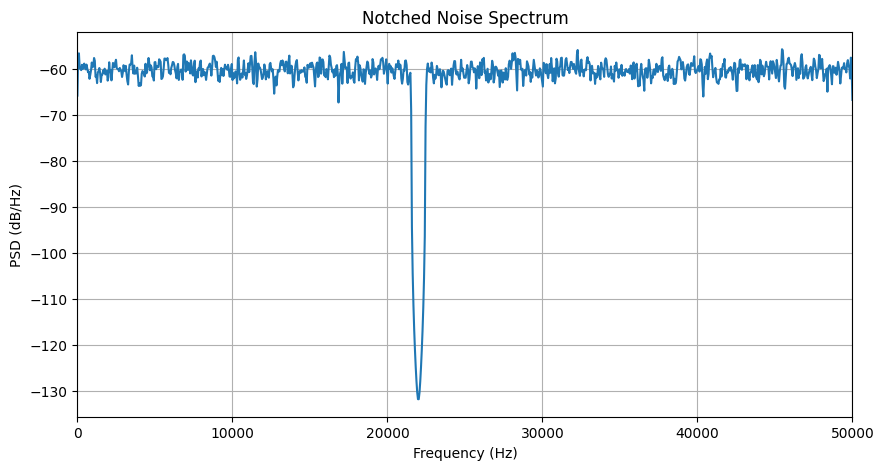

In [4]:
fs = 1 / dt

f, psd = welch(
    x,
    fs=fs,
    nperseg=min(2048, len(x))
)

plt.figure(figsize=(10, 5))

plt.plot(
    f,
    10 * np.log10(psd + 1e-20)
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Notched Noise Spectrum")

plt.xlim(0, fs / 2)
plt.grid()

plt.show()

### with cnmodel

In [2]:
stimpar = {
    "dur": 0.26,
    "pip": 0.1,
    "start": [0.1],
    "baseline": [50, 150],
    "response": [150, 250],
}

In [4]:
db = 60
seed = 34657845
stim = sound.NoisePip(
    rate=100e3,
    duration=stimpar["dur"],
    dbspl=db,
    ramp_duration=2.5e-3,
    pip_duration=stimpar["pip"],
    pip_start=stimpar["start"],
    seed=seed
)

In [7]:
dt = stim.time[1] - stim.time[0]

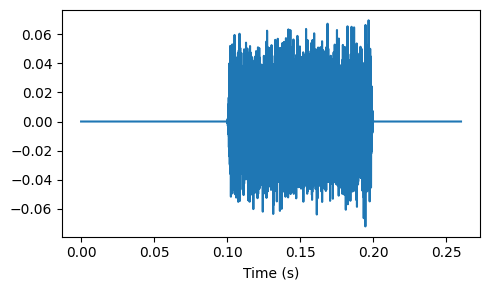

In [5]:
fig, axs = plt.subplots(1,1,figsize=(5,3))
axs.plot(stim.time, stim.sound)
axs.set_xlabel('Time (s)')
# axs.set_xlim([0.145,0.15])
fig.tight_layout()

In [8]:
N = len(stim.sound)
X = np.fft.rfft(stim.sound)
freq = np.fft.rfftfreq(N, d=dt)

center_freq = 22000
width = 1000

f_low = center_freq - width / 2
f_high = center_freq + width / 2
idx = (freq >= f_low) & (freq <= f_high)
X[idx] = 0

x = np.fft.irfft(X, n=N)
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

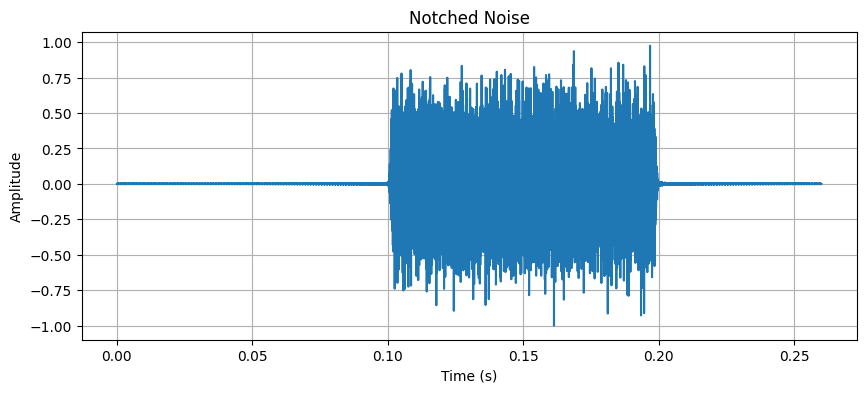

In [9]:
plt.figure(figsize=(10, 4))

plt.plot(stim.time, x)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Notched Noise")

# plt.xlim(0, 5)
plt.grid()

plt.show()

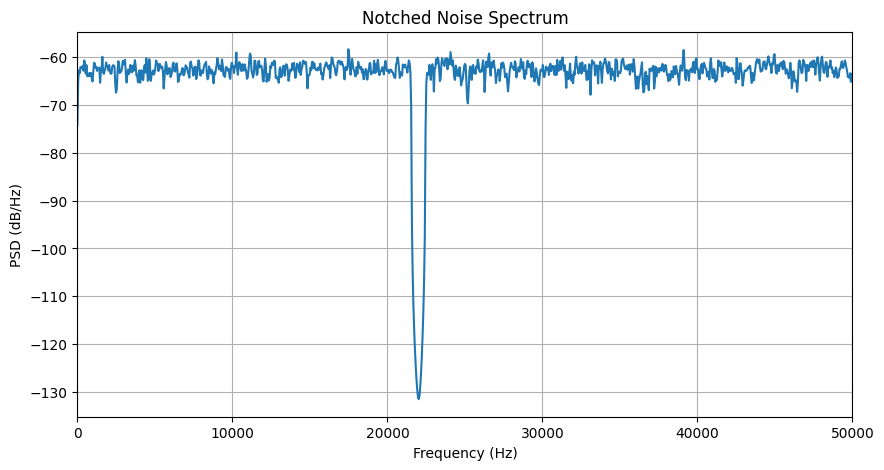

In [10]:
fs = 1 / dt

f, psd = welch(
    x,
    fs=fs,
    nperseg=min(2048, len(x))
)

plt.figure(figsize=(10, 5))

plt.plot(
    f,
    10 * np.log10(psd + 1e-20)
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Notched Noise Spectrum")

plt.xlim(0, fs / 2)
plt.grid()

plt.show()

In [12]:
stim.sound = x

In [13]:
stim.sound[13000]

np.float64(-0.023868097941151457)

In [21]:
x[13000]

np.float64(-0.023868097941151457)

In [23]:
stim

In [25]:
wavfile.write('notch_22kHz.wav', int(fs), x.astype(np.float32))

In [32]:
stim_wav = sound.ReadWavefile('notch_22kHz.wav', rate=fs, dbspl=60)

In [38]:
stim_wav.sound.shape

(26001,)

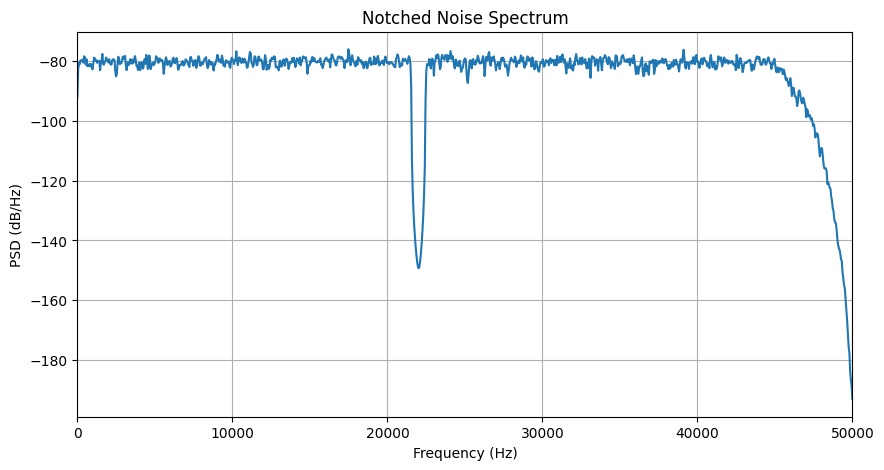

In [40]:
fs = 1 / (stim_wav.time[1] - stim_wav.time[0])

f, psd = welch(
    stim_wav.sound,
    fs=fs,
    nperseg=min(2048, len(stim_wav.sound))
)

plt.figure(figsize=(10, 5))

plt.plot(
    f,
    10 * np.log10(psd + 1e-20)
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Notched Noise Spectrum")

plt.xlim(0, fs / 2)
plt.grid()

plt.show()